# NCD Burden in Africa vs the USA — Diabetes & Cardiovascular Disease
### Exploratory Data Analysis

This notebook explores the **non-communicable disease (NCD) burden** — with a focus on **diabetes** and the
**cardiovascular / chronic-disease share of mortality** — across the 54 African countries and the United States.

**Data (World Bank Indicators API, sourced from IDF / WHO-GHE estimates):**

| Key | Code | Meaning |
|---|---|---|
| `diabetes_prevalence` | `SH.STA.DIAB.ZS` | Diabetes prevalence, % of population aged 20–79 |
| `ncd_deaths` | `SH.DTH.NCOM.ZS` | Deaths caused by NCDs (CVD, cancer, diabetes, chronic respiratory), % of all deaths |
| `ncd_mortality_30_70` | `SH.DYN.NCOM.ZS` | Probability of dying between 30 and 70 from CVD, cancer, diabetes or CRD (%) |

The notebook reads the **actual CSV files** produced by the pipeline (`data/processed/`), and falls back to the raw
CSVs in `data/raw/` (running the transformation in-process) if the processed layer has not been built yet.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+notebook_connected"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
print("Project root:", PROJECT_ROOT)
print("Raw files:", sorted(p.name for p in RAW_DIR.glob("*.csv")))

Project root: /home/ubuntu/github_repos/Data-Analytic-Data-Engineering/2026-11-13_health_africa_usa_ncd_diabetes_cardiovascular
Raw files: ['diabetes_prevalence.csv', 'ncd_deaths.csv']


## 1. Load the data
If `data/processed/ncd_observations.csv` is missing, the transformation module is imported and executed on the
raw World Bank CSVs so the notebook is always runnable from a fresh clone.

In [2]:
obs_path = PROCESSED_DIR / "ncd_observations.csv"
if not obs_path.exists():
    sys.path.insert(0, str(PROJECT_ROOT / "src" / "transformation"))
    import transform as tr
    tr.setup_logging("WARNING")
    tr.transform(tr.load_config())

obs = pd.read_csv(obs_path)
countries = pd.read_csv(PROCESSED_DIR / "countries.csv")
raw_diab = pd.read_csv(RAW_DIR / "diabetes_prevalence.csv")
raw_ncd = pd.read_csv(RAW_DIR / "ncd_deaths.csv")

print(f"Raw diabetes rows: {len(raw_diab)} | raw NCD-death rows: {len(raw_ncd)}")
print(f"Clean observations: {len(obs)} across {obs['iso3'].nunique()} entities")
obs.groupby(["indicator_key", "region_group"]).size().unstack(fill_value=0)

Raw diabetes rows: 525 | raw NCD-death rows: 455
Clean observations: 952 across 253 entities


region_group,Africa,Aggregate,Benchmark,Other,USA
indicator_key,,,,,
diabetes_prevalence,109,74,12,320,2
ncd_deaths,70,185,30,150,0


### Data-quality notes
* Rows with missing values are removed in the transformation layer; values are validated to lie in 0–100 %.
* Diabetes prevalence is published for survey years **2000, 2011 and 2024** (IDF Diabetes Atlas editions).
* The NCD-death snapshot in `data/raw/` contains the first API page only, so it covers World Bank aggregates and
  countries alphabetically up to *Cuba*: **14 African countries** and **no US country row**.
  The **North America (NAC)** aggregate — ~90 % of whose population is the USA — is therefore used as the US proxy
  for NCD mortality. Re-running `src/ingestion/ingest.py` (which paginates through every page) fills this gap.

In [3]:
for key, grp in obs.groupby("indicator_key"):
    print(f"{key:22s} years={sorted(grp['year'].unique())}")

usa_rows = obs[obs["iso3"].isin(["USA", "NAC"])]
usa_rows.pivot_table(index=["iso3", "indicator_key"], columns="year", values="value")

diabetes_prevalence    years=[2000, 2011, 2024]
ncd_deaths             years=[2010, 2015, 2019, 2020, 2021]


year                         2010    2011     2015     2019     2020     2021  \
iso3 indicator_key                                                              
NAC  diabetes_prevalence      NaN  9.2978      NaN      NaN      NaN      NaN   
     ncd_deaths           88.0361     NaN  87.8943  88.3158  79.4479  78.1115   
USA  diabetes_prevalence      NaN  9.4000      NaN      NaN      NaN      NaN   

year                         2024  
iso3 indicator_key                 
NAC  diabetes_prevalence  13.0353  
     ncd_deaths               NaN  
USA  diabetes_prevalence  13.7000

## 2. Diabetes prevalence — where does Africa stand against the USA?

In [4]:
diab = obs[obs["indicator_key"] == "diabetes_prevalence"]
latest_year = diab["year"].max()
diab_latest = diab[diab["year"] == latest_year]
usa_diab = diab_latest.loc[diab_latest["iso3"] == "USA", "value"].iloc[0]
africa_latest = diab_latest[diab_latest["region_group"] == "Africa"].sort_values("value", ascending=False)

print(f"Latest year: {latest_year}")
print(f"USA diabetes prevalence: {usa_diab:.1f}%")
print(f"Africa (54 countries) mean: {africa_latest['value'].mean():.2f}% | median: {africa_latest['value'].median():.2f}%")
print(f"African countries above the USA: {(africa_latest['value'] > usa_diab).sum()}")
africa_latest[["country_name", "africa_subregion", "value"]].head(10)

Latest year: 2024
USA diabetes prevalence: 13.7%
Africa (54 countries) mean: 7.39% | median: 5.75%
African countries above the USA: 6


,country_name,africa_subregion,value
388,"Egypt, Arab Rep.",North Africa,22.4
671,Mauritius,East Africa,20.1
786,Sudan,North Africa,19.0
349,Algeria,North Africa,17.5
907,Tunisia,North Africa,16.0
572,Libya,North Africa,15.8
826,Sao Tome and Principe,Central Africa,12.1
618,Morocco,North Africa,11.9
295,Comoros,East Africa,10.8
949,Zambia,East Africa,10.3


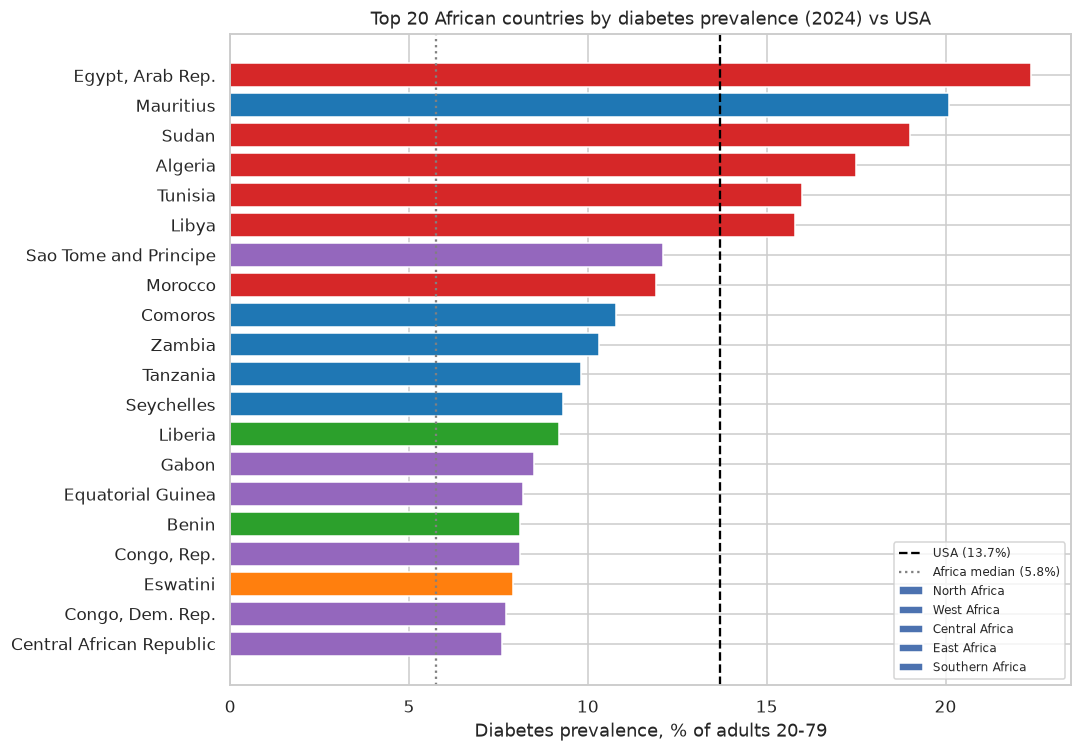

In [5]:
# Visualisation 1 - Top 20 African countries vs the USA (matplotlib)
top = africa_latest.head(20).iloc[::-1]
palette = {"North Africa": "#d62728", "West Africa": "#2ca02c", "Central Africa": "#9467bd",
           "East Africa": "#1f77b4", "Southern Africa": "#ff7f0e"}
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["country_name"], top["value"], color=top["africa_subregion"].map(palette))
ax.axvline(usa_diab, color="black", ls="--", lw=1.5, label=f"USA ({usa_diab:.1f}%)")
ax.axvline(africa_latest["value"].median(), color="grey", ls=":", lw=1.5,
           label=f"Africa median ({africa_latest['value'].median():.1f}%)")
for sub, col in palette.items():
    ax.barh([], [], color=col, label=sub)
ax.set_xlabel("Diabetes prevalence, % of adults 20-79")
ax.set_title(f"Top 20 African countries by diabetes prevalence ({latest_year}) vs USA")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** North Africa forms a distinct high-burden cluster — Egypt, Sudan, Algeria, Tunisia and Libya all
exceed the US rate, as does the island state of Mauritius. Sub-Saharan prevalence is mostly far below the US,
but that is partly a reflection of under-diagnosis and younger population age structures.

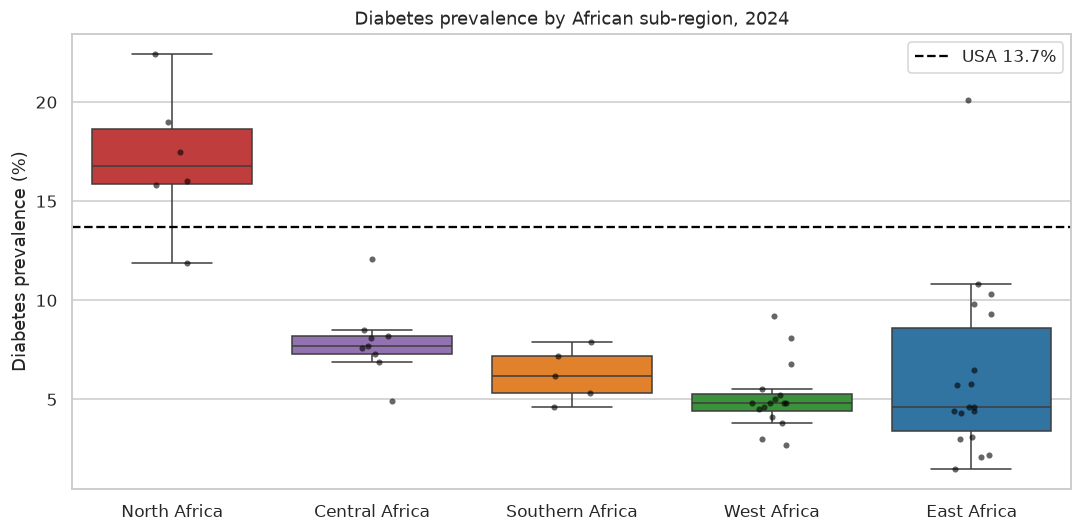

,count,mean,median,max
africa_subregion,,,,
Central Africa,9,7.92,7.70,12.1
East Africa,18,6.25,4.60,20.1
North Africa,6,17.10,16.75,22.4
Southern Africa,5,6.24,6.20,7.9
West Africa,16,5.11,4.80,9.2


In [6]:
# Visualisation 2 - Distribution by African sub-region (seaborn box + strip)
order = (africa_latest.groupby("africa_subregion")["value"].median()
         .sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=africa_latest, x="africa_subregion", y="value", order=order,
            palette=palette, ax=ax, showfliers=False)
sns.stripplot(data=africa_latest, x="africa_subregion", y="value", order=order,
              color="black", size=4, alpha=0.6, ax=ax)
ax.axhline(usa_diab, color="black", ls="--", label=f"USA {usa_diab:.1f}%")
ax.set_xlabel("")
ax.set_ylabel("Diabetes prevalence (%)")
ax.set_title(f"Diabetes prevalence by African sub-region, {latest_year}")
ax.legend()
plt.tight_layout()
plt.show()

africa_latest.groupby("africa_subregion")["value"].agg(["count", "mean", "median", "max"]).round(2)

## 3. How fast is the burden growing? (2011 → 2024)

Countries with both years: 54
African countries where prevalence rose: 40 of 53
USA change: +4.3 pp


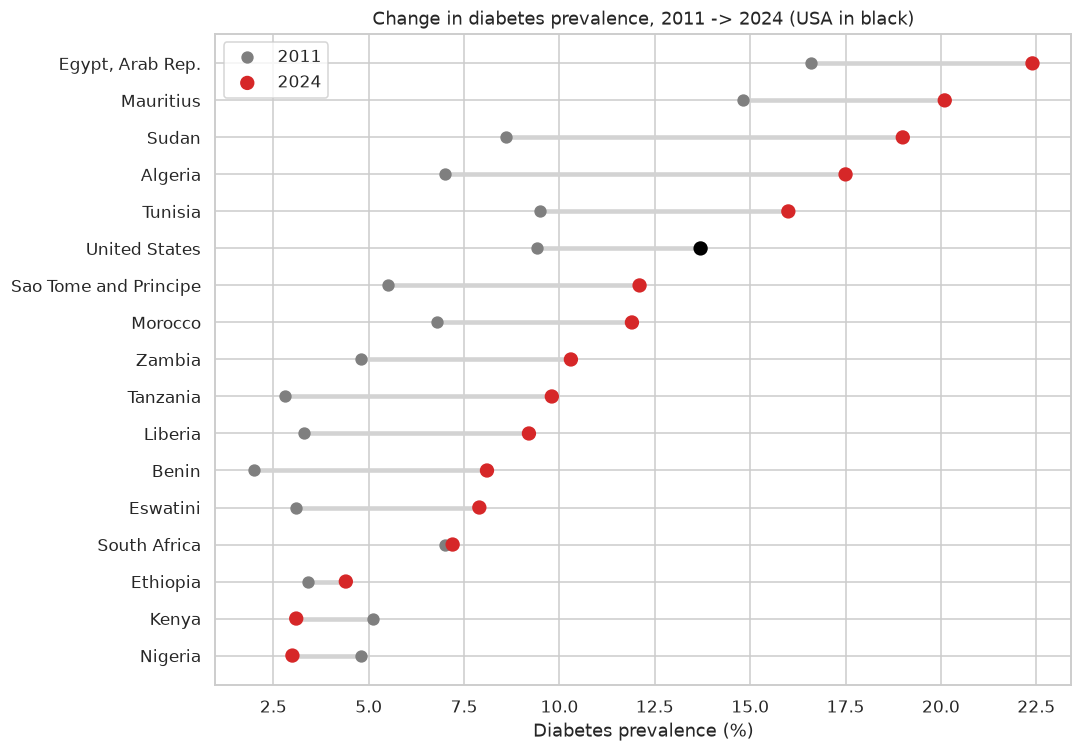

In [7]:
pair = (diab[diab["year"].isin([2011, latest_year]) & diab["region_group"].isin(["Africa", "USA"])]
        .pivot_table(index=["iso3", "country_name", "region_group"], columns="year", values="value")
        .dropna().reset_index())
pair["change_pp"] = pair[latest_year] - pair[2011]
print(f"Countries with both years: {len(pair)}")
af_pair = pair[pair["region_group"] == "Africa"]
print(f"African countries where prevalence rose: {(af_pair['change_pp'] > 0).sum()} of {len(af_pair)}")
print(f"USA change: {pair.loc[pair['iso3'] == 'USA', 'change_pp'].iloc[0]:+.1f} pp")

# Visualisation 3 - dumbbell chart of 2011 -> latest for biggest movers + USA + giants
focus_iso = (set(pair.nlargest(12, "change_pp")["iso3"]) | {"USA", "NGA", "ZAF", "KEN", "ETH", "EGY"})
d = pair[pair["iso3"].isin(focus_iso)].sort_values(latest_year)
fig, ax = plt.subplots(figsize=(10, 7))
ax.hlines(d["country_name"], d[2011], d[latest_year], color="lightgrey", lw=3)
ax.scatter(d[2011], d["country_name"], color="#7f7f7f", s=50, label="2011", zorder=3)
colors = np.where(d["region_group"] == "USA", "#000000", "#d62728")
ax.scatter(d[latest_year], d["country_name"], color=colors, s=70, label=str(latest_year), zorder=3)
ax.set_xlabel("Diabetes prevalence (%)")
ax.set_title(f"Change in diabetes prevalence, 2011 -> {latest_year} (USA in black)")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** The fastest absolute increases since 2011 are in Algeria and Sudan (≈ +10 pp), with large relative
jumps in Tanzania, Benin and Liberia. The USA rose ~4 pp over the same period. A minority of countries (e.g.
Nigeria, Kenya) show declines, which largely reflects methodological revisions between Diabetes Atlas editions.

In [8]:
# Visualisation 4 - Interactive choropleth (plotly) of the latest diabetes prevalence, Africa + USA
map_df = diab_latest[diab_latest["region_group"].isin(["Africa", "USA"])]
fig = px.choropleth(
    map_df, locations="iso3", color="value", hover_name="country_name",
    color_continuous_scale="Reds", range_color=(0, map_df["value"].max()),
    labels={"value": "Diabetes %"},
    title=f"Diabetes prevalence (% adults 20-79), Africa & USA, {latest_year}",
)
fig.update_geos(showcountries=True, lataxis_range=[-40, 60], lonaxis_range=[-130, 60])
fig.update_layout(height=520, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

## 4. The epidemiological transition — NCD share of all deaths
NCDs (dominated by cardiovascular disease) account for the overwhelming majority of deaths in North America but
roughly one-third in Sub-Saharan Africa, where infectious, maternal and neonatal causes still dominate.
That share has been climbing steadily — the **double burden** of disease.

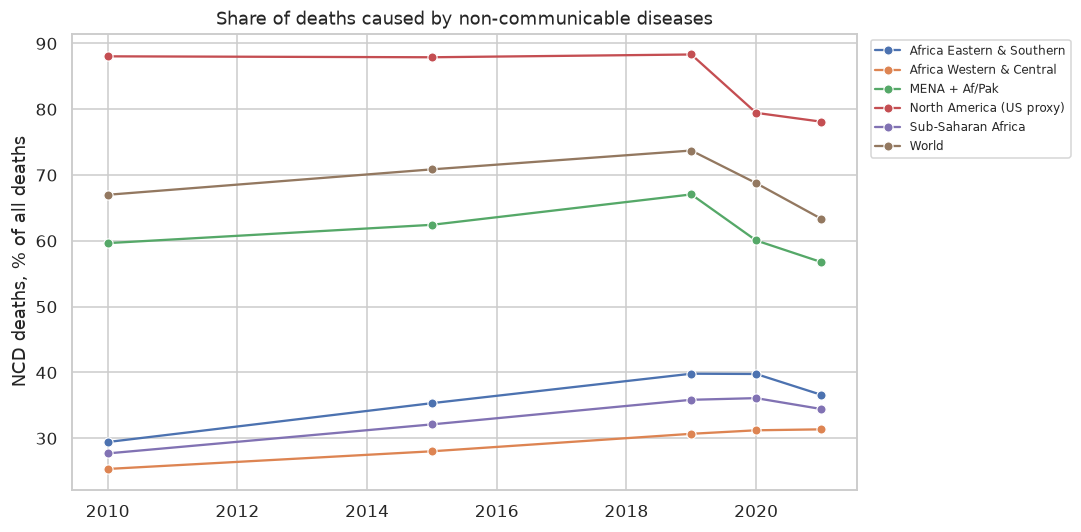

year,2010,2015,2019,2020,2021
region,,,,,
Africa Eastern & Southern,29.4,35.3,39.8,39.8,36.6
Africa Western & Central,25.3,28.0,30.7,31.2,31.4
MENA + Af/Pak,59.7,62.4,67.1,60.1,56.8
North America (US proxy),88.0,87.9,88.3,79.4,78.1
Sub-Saharan Africa,27.7,32.1,35.8,36.1,34.5
World,67.0,70.9,73.7,68.8,63.4


In [9]:
ncd = obs[obs["indicator_key"] == "ncd_deaths"]
regions = {"NAC": "North America (US proxy)", "WLD": "World", "MEA": "MENA + Af/Pak",
           "SSF": "Sub-Saharan Africa", "AFE": "Africa Eastern & Southern", "AFW": "Africa Western & Central"}
trend = ncd[ncd["iso3"].isin(regions)].assign(region=lambda x: x["iso3"].map(regions))

# Visualisation 5 - NCD share of deaths over time (seaborn line)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=trend, x="year", y="value", hue="region", marker="o", ax=ax)
ax.set_ylabel("NCD deaths, % of all deaths")
ax.set_xlabel("")
ax.set_title("Share of deaths caused by non-communicable diseases")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

trend.pivot_table(index="region", columns="year", values="value").round(1)

**Insight:** In Sub-Saharan Africa the NCD share of deaths rose from ~28 % (2010) to ~36 % (2019–2020), while
North America stays near 88 % pre-pandemic. The 2020–2021 dip everywhere is a COVID-19 artefact: a surge of
communicable-disease deaths lowers the NCD *share* without NCD deaths falling.

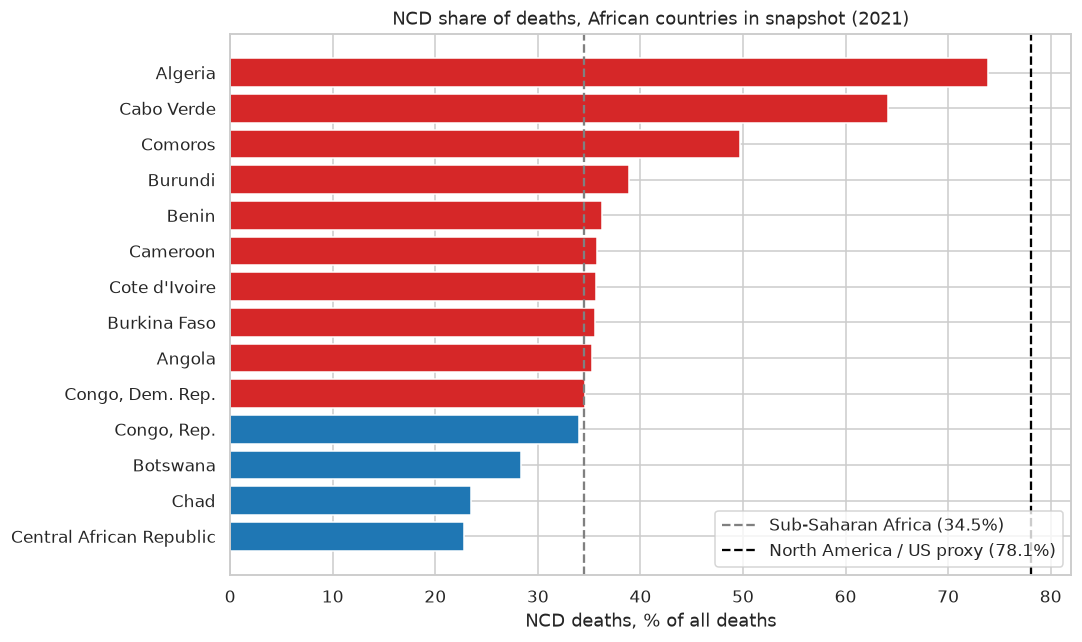

In [10]:
# Visualisation 6 - African countries with NCD-death data vs SSA and US proxy (matplotlib)
ncd_latest = ncd[(ncd["is_latest"] == 1) & (ncd["region_group"] == "Africa")].sort_values("value")
ssf_val = ncd[(ncd["iso3"] == "SSF") & (ncd["year"] == ncd_latest["year"].max())]["value"].iloc[0]
nac_val = ncd[(ncd["iso3"] == "NAC") & (ncd["year"] == ncd_latest["year"].max())]["value"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ncd_latest["country_name"], ncd_latest["value"],
        color=np.where(ncd_latest["value"] > ssf_val, "#d62728", "#1f77b4"))
ax.axvline(ssf_val, color="grey", ls="--", label=f"Sub-Saharan Africa ({ssf_val:.1f}%)")
ax.axvline(nac_val, color="black", ls="--", label=f"North America / US proxy ({nac_val:.1f}%)")
ax.set_xlabel("NCD deaths, % of all deaths")
ax.set_title(f"NCD share of deaths, African countries in snapshot ({ncd_latest['year'].max()})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5. Linking metabolic risk to mortality

In [11]:
# Visualisation 7 - Diabetes prevalence vs NCD share of deaths (plotly scatter)
latest_vals = (obs[(obs["is_latest"] == 1) & obs["region_group"].isin(["Africa", "USA", "Benchmark"])]
               .pivot_table(index=["iso3", "country_name", "region_group"], columns="indicator_key",
                            values="value").reset_index())
both = latest_vals.dropna(subset=["diabetes_prevalence", "ncd_deaths"])
fig = px.scatter(
    both, x="diabetes_prevalence", y="ncd_deaths", color="region_group", text="iso3",
    hover_name="country_name",
    labels={"diabetes_prevalence": "Diabetes prevalence (%)", "ncd_deaths": "NCD share of deaths (%)"},
    title="Diabetes prevalence vs NCD share of deaths (latest available year)",
)
fig.update_traces(textposition="top center", marker=dict(size=11))
fig.update_layout(height=520)
fig.show()

corr = both[["diabetes_prevalence", "ncd_deaths"]].corr().iloc[0, 1]
print(f"Pearson correlation (n={len(both)}): {corr:.2f}")

Pearson correlation (n=20): 0.70


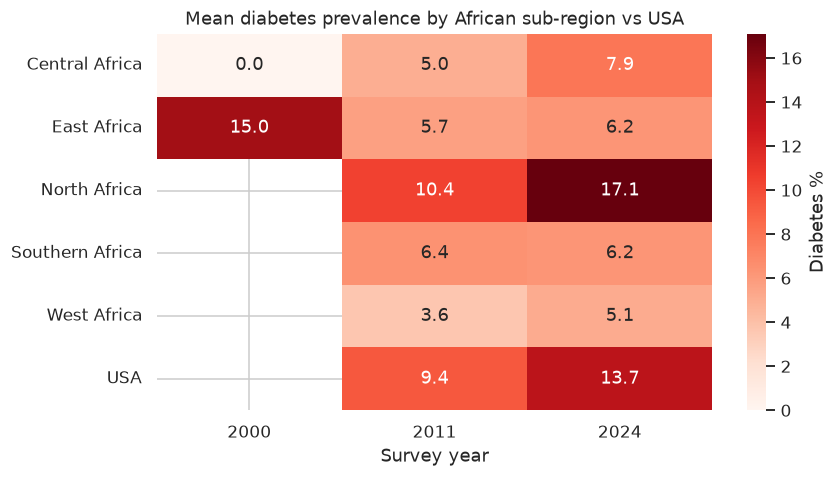

In [12]:
# Visualisation 8 - Heatmap: mean diabetes prevalence by sub-region and survey year (seaborn)
heat = (diab[diab["region_group"] == "Africa"]
        .pivot_table(index="africa_subregion", columns="year", values="value", aggfunc="mean"))
usa_series = diab[diab["iso3"] == "USA"].set_index("year")["value"].rename("USA")
heat = pd.concat([heat, usa_series.to_frame().T])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Diabetes %"}, ax=ax)
ax.set_title("Mean diabetes prevalence by African sub-region vs USA")
ax.set_xlabel("Survey year")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Summary statistics

In [13]:
summary = pd.DataFrame({
    "USA diabetes % (latest)": [usa_diab],
    "Africa mean diabetes %": [africa_latest["value"].mean()],
    "North Africa mean diabetes %": [africa_latest.query("africa_subregion == 'North Africa'")["value"].mean()],
    "Sub-Saharan mean diabetes %": [africa_latest.query("africa_subregion != 'North Africa'")["value"].mean()],
    "SSA NCD death share %": [ssf_val],
    "North America NCD death share %": [nac_val],
}).T.round(2)
summary.columns = ["value"]
summary

,value
USA diabetes % (latest),13.70
Africa mean diabetes %,7.39
North Africa mean diabetes %,17.10
Sub-Saharan mean diabetes %,6.18
SSA NCD death share %,34.45
North America NCD death share %,78.11


## 7. Key findings

1. **The US carries a heavier average diabetes burden than Africa** — 13.7 % of US adults (2024) versus an
   African country mean of ~7.4 %; yet **six African countries exceed the US**, five of them in North Africa
   (Egypt 22.4 %, Sudan 19.0 %, Algeria 17.5 %, Tunisia 16.0 %, Libya 15.8 %) plus Mauritius (20.1 %).
2. **North Africa is ~1.25× the US rate** on average; West Africa is the lowest-burden sub-region (~0.37× the US).
3. **Diabetes is rising across most of the continent.** Algeria and Sudan added ~10 percentage points since 2011;
   the US added ~4 pp.
4. **Africa is mid-transition.** NCDs caused roughly a third of deaths in Sub-Saharan Africa in 2021 versus
   ~78 % in North America — but the SSA share has climbed ~7 pp since 2010, signalling a growing cardiovascular
   and metabolic disease load on health systems still fighting infectious disease.
5. **Data gaps matter.** Low measured prevalence in many Sub-Saharan countries coincides with limited screening;
   investment in NCD surveillance (WHO STEPS surveys) is a prerequisite for targeting interventions.

*Sources: World Bank WDI (SH.STA.DIAB.ZS, SH.DTH.NCOM.ZS, SH.DYN.NCOM.ZS); WHO Global Health Observatory NCD theme.*